# Huấn luyện FPT v2: baseline và LSTM

Notebook này gọi cùng module `src/models/experiment.py` trên local hoặc Colab.
Chỉ dùng snapshot CSV có hash khớp metadata; không tự tải dữ liệu mới khi thiếu file.


**Lưu ý thực nghiệm:** năm 2025 đã được xem trong lần thử trước. Kết quả dưới đây là đánh giá lịch sử được sử dụng lại, không gọi là holdout hoàn toàn chưa từng xem.

**GitHub/Colab v2:** setup tự clone nhánh `feature/train-model` vào thư mục riêng, cài môi trường và phục hồi snapshot có hash. Nếu Colab yêu cầu restart sau cài thư viện, restart session rồi Run all lại. Không mở notebook cũ trong Drive để lấy kết quả chính thức.

## CPU reference đã chốt

Run `20261025T121448987851Z`: 1.087 train, 493 validation, 248 test lịch sử. Train Mean thắng validation; LSTM lookback 30 là model ML dùng demo. LSTM test RMSE 0.019858, MAE 0.013442, Hit Rate 54.98% trên 211 actual khác 0. Kết quả Colab của lần chạy mới nằm ở cuối notebook và được đối chiếu riêng, không thay CPU reference.

## 1. Môi trường và nguồn dữ liệu

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.metadata
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    ROOT = Path('/content/Stock_Prediction_Project_v2')
    if not (ROOT / '.git').exists():
        subprocess.check_call(['git', 'clone', '--depth', '1', '--branch', 'feature/train-model',
                               'https://github.com/PhucTruong11/Stock_Prediction_Project.git', str(ROOT)])
    loaded_versions = {name: getattr(sys.modules.get(name), '__version__', None)
                       for name in ['numpy', 'pandas', 'sklearn', 'tensorflow', 'xgboost']}
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT / 'requirements-colab.txt')])
    packages = {'sklearn': 'scikit-learn', 'numpy': 'numpy', 'pandas': 'pandas', 'tensorflow': 'tensorflow', 'xgboost': 'xgboost'}
    changed = [name for name, old in loaded_versions.items()
               if old is not None and old != importlib.metadata.version(packages[name])]
    if changed:
        raise RuntimeError('Dependencies changed: ' + str(changed) + '. Restart the Colab session, then Run all again.')
else:
    candidates = [Path(os.environ.get('FPT_PROJECT_ROOT', Path.cwd())), Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / 'src/models/experiment.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the complete updated project.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.snapshot import restore_snapshot
restore_snapshot(ROOT)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.models.experiment import load_data, split_masks, run_experiment, evaluate_saved
from src.features.build_features import FEATURE_COLUMNS, TARGET_COLUMN
plt.rcParams.update({'figure.figsize': (11, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print('Project:', ROOT)
print('Exact shared snapshot restored; no Yahoo download.')


Project: D:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project
Exact shared snapshot restored; no Yahoo download.


In [2]:
features, labels, data_metadata = load_data(ROOT)
masks = split_masks(labels)
display(pd.DataFrame([
    {'split': name, 'samples': int(mask.sum()),
     'origin_start': labels.loc[mask, 'Date'].min(),
     'origin_end': labels.loc[mask, 'Date'].max(),
     'last_target': labels.loc[mask, 'Target_Date_1d'].max()}
    for name, mask in masks.items()
]))
print('Inputs:', len(FEATURE_COLUMNS), '| Raw SHA256:', data_metadata['source_raw_sha256'])
print('All models use the same eligible dates and at least 60 rows of past context.')

,split,samples,origin_start,origin_end,last_target
0,train,1087,2018-06-19,2022-12-29,2022-12-30
1,validation,493,2023-01-03,2024-12-30,2024-12-31
2,test,248,2025-01-02,2025-12-30,2025-12-31


Inputs: 16 | Raw SHA256: 501d6a8e0c511dca824994bdd8e91c58e222506eef667780eb15433c2070c8ea
All models use the same eligible dates and at least 60 rows of past context.


## 2. Phương pháp và lựa chọn cấu hình

- Train tới 2022; validation 2023–2024; test 2025. Nhãn vượt ranh giới bị loại.
- Cửa sổ LSTM bao gồm ngày dự báo, lấy từ lịch sử features đầy đủ.
- Scaler fit trên lịch sử train; mọi model dùng chung ngày train/validation/test.
- So sánh zero-return, persistence-return, train-mean, always-up, LR, Ridge, XGBoost và LSTM.
- Ridge thử 3 alpha; XGBoost thử 2 độ sâu; LSTM thử lookback 10/30/60, một lớp 32 units.
- Chọn theo **validation RMSE**; ghi `selection.json` trước khi dự đoán test. Không xem test từng trial.
- Zero-return có directional accuracy **N/A**, không gán 50%. Ngày thực tế đứng giá được báo riêng; dự báo 0 không giúp tăng accuracy bằng cách bỏ mẫu.

In [3]:
EPOCHS = 40
SEED = 42
result = run_experiment(ROOT, include_lstm=True, epochs=EPOCHS, seed=SEED)
REPORT_DIR = ROOT / result['report_dir']
ARTIFACT_DIR = ROOT / result['artifact_dir']
manifest = result['manifest']
scores = result['metrics']
print('Artifacts:', ARTIFACT_DIR)
print('Reports:', REPORT_DIR)

Run 20261025T121448987851Z; common samples: train=1087, validation=493, test=248


Zero-Return: validation RMSE=0.0140950


Return Persistence: validation RMSE=0.0190693


Train Mean: validation RMSE=0.0139814


Always Up: validation RMSE=0.0174702


...

LSTM/30: validation RMSE=0.0140327


Training LSTM lookback=60 on CPU...


LSTM/60: validation RMSE=0.0140788


Selected on validation: Train Mean; reports -> D:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project\reports\experiments\20261025T121448987851Z


Artifacts: D:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project\models\experiments\20261025T121448987851Z
Reports: D:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project\reports\experiments\20261025T121448987851Z


## 3. Validation và ablation lookback

,candidate,family,rmse,mae,hit_rate_pct,direction_coverage_pct
0,Zero-Return,Zero-Return,0.014095,0.010102,NaN,0.000000
1,Return Persistence,Return Persistence,0.019069,0.014454,48.922414,94.612069
2,Train Mean,Train Mean,0.013981,0.010076,54.741379,100.000000
3,Always Up,Always Up,0.017470,0.014261,54.741379,100.000000
4,Linear Regression/0,Linear Regression,0.014051,0.010104,51.724138,100.000000
5,Ridge/0,Ridge,0.014051,0.010103,51.724138,100.000000
6,Ridge/1,Ridge,0.014050,0.010101,51.724138,100.000000
7,Ridge/2,Ridge,0.014035,0.010085,50.646552,100.000000
8,XGBoost/0,XGBoost,0.014046,0.010060,56.034483,100.000000
9,XGBoost/1,XGBoost,0.014074,0.010075,54.741379,100.000000


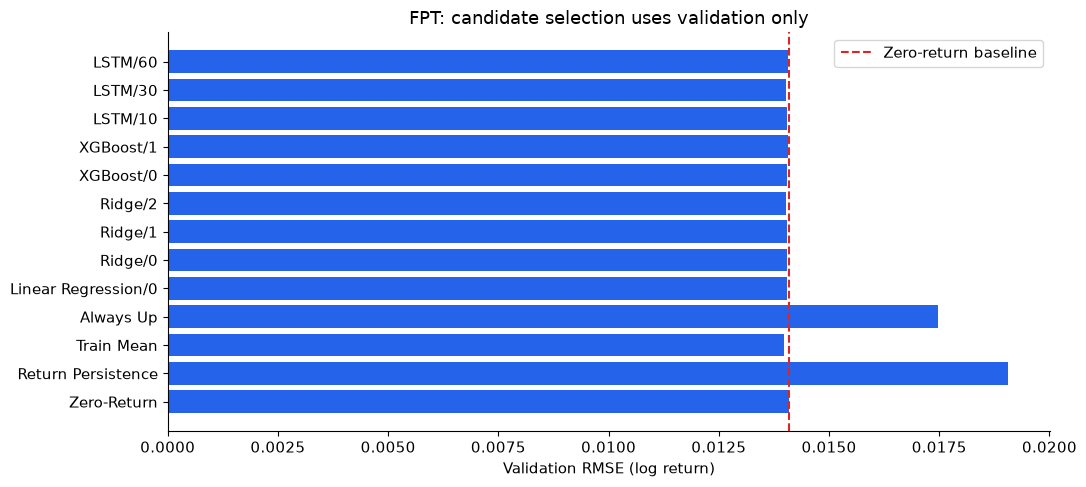

In [4]:
trials = pd.read_csv(REPORT_DIR / 'validation_trials.csv')
display(trials[['candidate', 'family', 'rmse', 'mae', 'hit_rate_pct', 'direction_coverage_pct']])
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(trials['candidate'], trials['rmse'], color='#2563eb')
zero_rmse = float(trials.loc[trials['candidate'].eq('Zero-Return'), 'rmse'].iloc[0])
ax.axvline(zero_rmse, color='#dc2626', linestyle='--', label='Zero-return baseline')
ax.set(xlabel='Validation RMSE (log return)', title='FPT: candidate selection uses validation only', xlim=(0, None))
ax.legend()
fig.tight_layout()
fig.savefig(REPORT_DIR / 'validation_candidates.png', dpi=160)
plt.show()

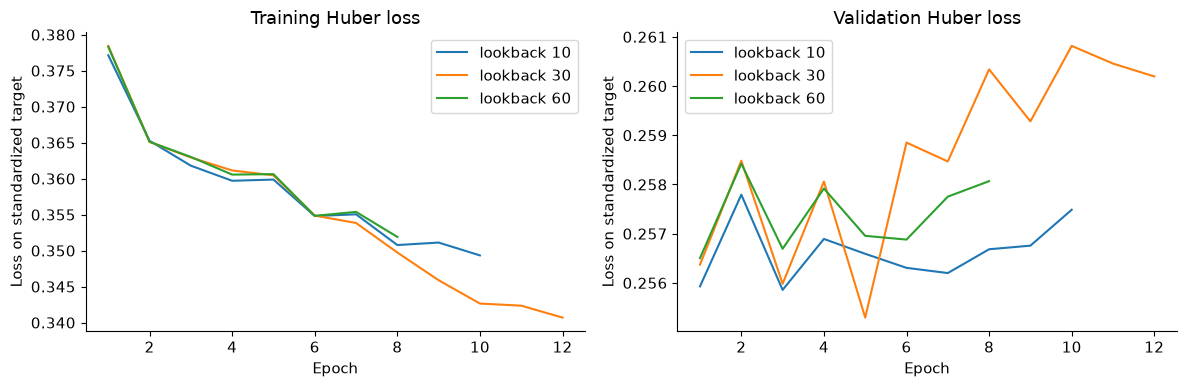

In [5]:
histories = json.loads((REPORT_DIR / 'lstm_history.json').read_text())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lb, history in histories.items():
    for ax, metric in zip(axes, ['loss', 'val_loss']):
        ax.plot(np.arange(1, len(history[metric]) + 1), history[metric], label=f'lookback {lb}')
for ax, title in zip(axes, ['Training Huber loss', 'Validation Huber loss']):
    ax.set(xlabel='Epoch', ylabel='Loss on standardized target', title=title)
    ax.legend()
fig.tight_layout()
fig.savefig(REPORT_DIR / 'learning_curves.png', dpi=160)
plt.show()

## 4. Cấu hình đã khóa và đánh giá test lịch sử

In [6]:
display(pd.Series(manifest['selection']))
display(scores.loc[scores['split'].eq('test'),
    ['model', 'n', 'rmse', 'mae', 'hit_rate_pct', 'direction_coverage_pct', 'mse_skill_vs_zero']])
print('Negative MSE skill means worse than predicting zero return.')

criterion                                             lowest validation RMSE
selected_model                                                    Train Mean
validation_rmse            {'Zero-Return': 0.01409504606857425, 'Return P...
test_used_for_selection                                                False
dtype: object

,model,n,rmse,mae,hit_rate_pct,direction_coverage_pct,mse_skill_vs_zero
8,Zero-Return,248,0.019917,0.013146,NaN,0.000000,0.000000
9,Return Persistence,248,0.027995,0.021221,36.018957,83.412322,-0.975684
10,Train Mean,248,0.020022,0.013429,45.023697,100.000000,-0.010523
11,Always Up,248,0.024133,0.019055,45.023697,100.000000,-0.468189
12,Linear Regression,248,0.020080,0.013623,52.132701,100.000000,-0.016373
13,Ridge,248,0.020055,0.013588,52.606635,100.000000,-0.013896
14,XGBoost,248,0.020017,0.013807,43.127962,100.000000,-0.010078
15,LSTM,248,0.019858,0.013442,54.976303,100.000000,0.005905


Negative MSE skill means worse than predicting zero return.


## 5. Diễn giải và bàn giao artifact

In [7]:
selected = manifest['selection']['selected_model']
selected_test = scores.loc[scores['split'].eq('test') & scores['model'].eq(selected)].iloc[0]
zero_test = scores.loc[scores['split'].eq('test') & scores['model'].eq('Zero-Return')].iloc[0]
display(Markdown(
    f"Model được chọn trên validation: **{selected}**. "
    f"Test RMSE = **{selected_test['rmse']:.6f}**, zero-return = **{zero_test['rmse']:.6f}**. "
    f"MSE skill = **{selected_test['mse_skill_vs_zero']:.2%}**. "
    "Không kết luận lợi nhuận giao dịch từ các chỉ số này. "
    "Manifest lưu model/scaler, seed, feature order, hash dữ liệu/artifact và phiên bản thư viện."
))
print('Run ID:', result['run_id'])

Model được chọn trên validation: **Train Mean**. Test RMSE = **0.020022**, zero-return = **0.019917**. MSE skill = **-1.05%**. Không kết luận lợi nhuận giao dịch từ các chỉ số này. Manifest lưu model/scaler, seed, feature order, hash dữ liệu/artifact và phiên bản thư viện.

Run ID: 20261025T121448987851Z


## Đối chiếu Colab với CPU reference

Cùng dữ liệu, code, split, seed và cấu hình. Tolerance RMSE 5% chỉ là ngưỡng kiểm tra kỹ thuật, không phải kiểm định thống kê. Không chọn lại model theo kết quả so sánh test.

In [8]:
reference_path = ROOT / 'models/reference_experiment.json'
if IN_COLAB and reference_path.exists():
    from src.models.compare_runs import compare_runs
    from src.models.experiment import save_json
    comparison = compare_runs(ARTIFACT_DIR, ROOT)
    save_json(REPORT_DIR / 'reference_comparison.json', comparison)
    display(pd.Series({key: value for key, value in comparison.items() if key != 'metrics'}))
    display(pd.DataFrame(comparison['metrics']))
    import zipfile
    export_path = Path('/content') / f"fpt-colab-{result['run_id']}.zip"
    with zipfile.ZipFile(export_path, 'w', zipfile.ZIP_DEFLATED) as archive:
        for folder in [ARTIFACT_DIR, REPORT_DIR]:
            for path in folder.rglob('*'):
                if path.is_file():
                    archive.write(path, path.relative_to(ROOT).as_posix())
    print('Result bundle:', export_path)
else:
    print('Local reference run; Colab comparison is performed on the subsequent run.')

Local reference run; Colab comparison is performed on the subsequent run.
